<a href="https://colab.research.google.com/github/MohabEldemery/12618839_plant-disease-detection/blob/main/12618839_Plant_Disease_Assignment_2_Enhanced.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 2 — Plant Disease Detection (Enhanced Experiment Notebook)

**Matriculation number:** 12618839

This version preserves the original baseline CNN and frozen MobileNetV2, adds MobileNetV2 partial fine-tuning, and measures robustness to darkened validation images. It uses the same Beans dataset and the same test split. New results must be obtained by running this notebook;


## 1. Install required packages
Colab generally includes TensorFlow; this installs the dataset loader and evaluation package. Run this cell once per fresh Colab session.

In [1]:
%pip -q install tensorflow-datasets scikit-learn importlib-resources

## 2. Import libraries and record your environment
A *library* is existing code that performs common tasks so you do not have to write everything yourself.

In [2]:
import json
import os
import platform
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import sklearn
import tensorflow as tf
import tensorflow_datasets as tfds
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report, confusion_matrix, f1_score

SEED = 42
IMG_SIZE = (160, 160)
BATCH_SIZE = 32
TARGET_ACCURACY = 0.80  # Goal only, not an achieved result.
EPOCHS_BASELINE = 7
EPOCHS_TRANSFER = 7

tf.keras.utils.set_random_seed(SEED)
Path("results").mkdir(exist_ok=True)

print("Python:", platform.python_version())
print("TensorFlow:", tf.__version__)
print("TensorFlow Datasets:", tfds.__version__)
print("scikit-learn:", sklearn.__version__)
print("GPU available:", bool(tf.config.list_physical_devices("GPU")))

Python: 3.13.18
TensorFlow: 2.21.0
TensorFlow Datasets: 4.9.10
scikit-learn: 1.6.1
GPU available: False


## 3. Download dataset
The [Beans dataset](https://www.tensorflow.org/datasets/catalog/beans) was collected in the field. It has three labels: `angular_leaf_spot`, `bean_rust`, `healthy`.

**Train** = data used to learn. **Validation** = data used to compare/select models. **Test** = data used only for final measurements. We keep these splits separate.

In [3]:

import time
import tensorflow_datasets as tfds
from tensorflow_datasets.datasets.beans import beans_dataset_builder

# Use Hugging Face because the original Google download returns HTTP 403.
base_url = "https://huggingface.co/datasets/AI-Lab-Makerere/beans/resolve/main/data"

beans_dataset_builder._TRAIN_URL = base_url + "/train.zip"
beans_dataset_builder._VALIDATION_URL = base_url + "/validation.zip"
beans_dataset_builder._TEST_URL = base_url + "/test.zip"

# Download the same Beans dataset from the alternative source.
data_start = time.perf_counter()

(train_raw, val_raw, test_raw), info = tfds.load(
    "beans",
    split=["train", "validation", "test"],
    as_supervised=True,
    with_info=True,
    shuffle_files=False,
)

DATA_SECONDS = time.perf_counter() - data_start
CLASS_NAMES = info.features["label"].names
NUM_CLASSES = len(CLASS_NAMES)

print("Categories:", CLASS_NAMES)

for split_name in ("train", "validation", "test"):
    print(split_name, ":", info.splits[split_name].num_examples, "images")

print("Dataset setup seconds:", round(DATA_SECONDS, 1))
assert NUM_CLASSES == 3


Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/3 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/beans/incomplete.HBRPOI_0.1.0/beans-train.tfrecord-[0-9][0-9][0-9][0-9][0-…

Generating validation examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/beans/incomplete.HBRPOI_0.1.0/beans-validation.tfrecord-[0-9][0-9][0-9][0-…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/beans/incomplete.HBRPOI_0.1.0/beans-test.tfrecord-[0-9][0-9][0-9][0-9][0-9…

Dataset beans downloaded and prepared to /root/tensorflow_datasets/beans/0.1.0. Subsequent calls will reuse this data.
Categories: ['angular_leaf_spot', 'bean_rust', 'healthy']
train : 1034 images
validation : 133 images
test : 128 images
Dataset setup seconds: 9.9


## 4. Resize images, create batches and test preprocessing
Images are resized to `160 × 160` pixels. Each batch contains up to 32 images. The models will handle scaling of pixel values internally.

In [4]:
def preprocess_image(image, label):
    """Resize a raw RGB image; preserve its integer class label."""
    image = tf.image.resize(tf.cast(image, tf.float32), IMG_SIZE)
    return image, tf.cast(label, tf.int32)


def create_dataset(raw_dataset, training=False):
    dataset = raw_dataset.map(preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)
    if training:
        dataset = dataset.shuffle(1034, seed=SEED, reshuffle_each_iteration=True)
    return dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = create_dataset(train_raw, training=True)
val_ds = create_dataset(val_raw)
test_ds = create_dataset(test_raw)

# TEST 1 — preprocessing produces the requested image size.
example_image = tf.ones((500, 500, 3), dtype=tf.uint8) * 125
processed_image, processed_label = preprocess_image(example_image, tf.constant(2))
assert tuple(processed_image.shape) == (160, 160, 3)
# TEST 2 — preprocessing does not corrupt labels or pixel values.
assert int(processed_label.numpy()) == 2
assert np.isclose(float(tf.reduce_mean(processed_image).numpy()), 125.0, atol=0.01)
# TEST 3 — batches have matching image/label counts.
first_images, first_labels = next(iter(train_ds))
assert first_images.shape[1:] == (160, 160, 3)
assert first_images.shape[0] == first_labels.shape[0]
print("Preprocessing tests passed (3 checks).")

Preprocessing tests passed (3 checks).


## 5. View example leaves
This confirms that the labels match the pictures. It also gives you a visualization for your report.

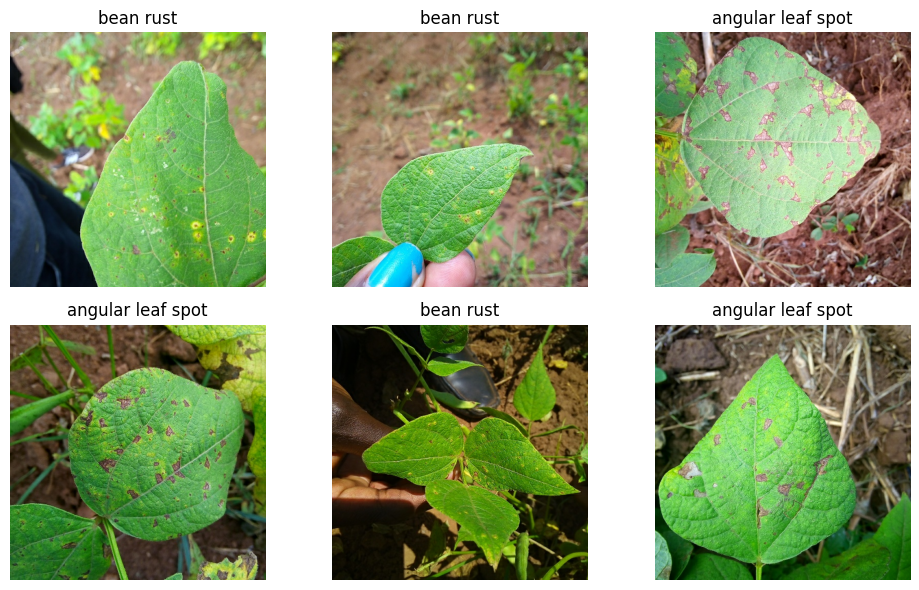

In [5]:
plt.figure(figsize=(10, 6))
for index, (image, label) in enumerate(train_raw.take(6)):
    plt.subplot(2, 3, index + 1)
    plt.imshow(image.numpy())
    plt.title(CLASS_NAMES[int(label.numpy())].replace("_", " "))
    plt.axis("off")
plt.tight_layout()
plt.show()

## 6. Train baseline CNN
A CNN learns features such as leaf spots, edges, and patterns. **Baseline** means our first working model, which we will later compare with a different approach. The target is **80% test accuracy**, but the achieved result must be measured after training.

In [6]:
def build_baseline_cnn():
    inputs = tf.keras.Input(shape=(*IMG_SIZE, 3))
    x = tf.keras.layers.Rescaling(1.0 / 255)(inputs)
    x = tf.keras.layers.Conv2D(24, 3, activation="relu", padding="same")(x)
    x = tf.keras.layers.MaxPooling2D()(x)
    x = tf.keras.layers.Conv2D(48, 3, activation="relu", padding="same")(x)
    x = tf.keras.layers.MaxPooling2D()(x)
    x = tf.keras.layers.Conv2D(64, 3, activation="relu", padding="same")(x)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dense(32, activation="relu")(x)
    outputs = tf.keras.layers.Dense(NUM_CLASSES, activation="softmax")(x)
    model = tf.keras.Model(inputs, outputs, name="baseline_cnn")
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model


def early_stopping():
    return tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=3, restore_best_weights=True
    )

baseline_model = build_baseline_cnn()
baseline_model.summary()
baseline_start = time.perf_counter()
baseline_history = baseline_model.fit(
    train_ds, validation_data=val_ds, epochs=EPOCHS_BASELINE,
    callbacks=[early_stopping()], verbose=2,
)
BASELINE_SECONDS = time.perf_counter() - baseline_start
print("Baseline training seconds:", round(BASELINE_SECONDS, 1))

Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 160, 160, 24)   │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 80, 80, 24)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 80, 80, 48)     │        10,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 40, 40, 48)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 40, 40, 64)     │        27,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 40,979 (160.07 KB)

 Trainable params: 40,979 (160.07 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/7
33/33 - 43s - 1s/step - accuracy: 0.3994 - loss: 1.0869 - val_accuracy: 0.4887 - val_loss: 1.0325
Epoch 2/7
33/33 - 37s - 1s/step - accuracy: 0.5542 - loss: 0.9727 - val_accuracy: 0.6241 - val_loss: 0.8689
Epoch 3/7
33/33 - 39s - 1s/step - accuracy: 0.6054 - loss: 0.8855 - val_accuracy: 0.5789 - val_loss: 0.8785
Epoch 4/7
33/33 - 41s - 1s/step - accuracy: 0.6431 - loss: 0.8370 - val_accuracy: 0.6466 - val_loss: 0.7984
Epoch 5/7
33/33 - 41s - 1s/step - accuracy: 0.6383 - loss: 0.8230 - val_accuracy: 0.6842 - val_loss: 0.8113
Epoch 6/7
33/33 - 34s - 1s/step - accuracy: 0.6286 - loss: 0.8400 - val_accuracy: 0.6917 - val_loss: 0.7392
Epoch 7/7
33/33 - 35s - 1s/step - accuracy: 0.6654 - loss: 0.7694 - val_accuracy: 0.5940 - val_loss: 0.7593
Baseline training seconds: 271.0


## 7. Train improved approach: pretrained MobileNetV2
A pretrained model already learned useful image patterns from another dataset. We **freeze** those learned layers and train a new classification head for our three bean-leaf classes. We add random image flips and rotations during training to try to improve generalization.

This is our first documented experiment: compare a CNN trained from scratch with a pretrained model plus augmentation. Improvement is a hypothesis, not a guarantee.

In [7]:
def build_transfer_model():
    # Pretrained weights are downloaded by Keras the first time this runs.
    backbone = tf.keras.applications.MobileNetV2(
        input_shape=(*IMG_SIZE, 3), include_top=False, weights="imagenet"
    )
    backbone.trainable = False

    inputs = tf.keras.Input(shape=(*IMG_SIZE, 3))
    x = tf.keras.layers.RandomFlip("horizontal")(inputs)
    x = tf.keras.layers.RandomRotation(0.08)(x)
    x = tf.keras.layers.RandomZoom(0.08)(x)
    # Same [-1, 1] pixel range expected by MobileNetV2.
    x = tf.keras.layers.Rescaling(1.0 / 127.5, offset=-1.0)(x)
    x = backbone(x, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dropout(0.25)(x)
    outputs = tf.keras.layers.Dense(NUM_CLASSES, activation="softmax")(x)
    model = tf.keras.Model(inputs, outputs, name="mobilenetv2_transfer")
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model

transfer_model = build_transfer_model()
transfer_model.summary()
transfer_start = time.perf_counter()
transfer_history = transfer_model.fit(
    train_ds, validation_data=val_ds, epochs=EPOCHS_TRANSFER,
    callbacks=[early_stopping()], verbose=2,
)
TRANSFER_SECONDS = time.perf_counter() - transfer_start
print("Transfer learning training seconds:", round(TRANSFER_SECONDS, 1))

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "mobilenetv2_transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 160, 160, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/7
33/33 - 30s - 920ms/step - accuracy: 0.4913 - loss: 1.1400 - val_accuracy: 0.6015 - val_loss: 0.8382
Epoch 2/7
33/33 - 24s - 725ms/step - accuracy: 0.6828 - loss: 0.7368 - val_accuracy: 0.6992 - val_loss: 0.6905
Epoch 3/7
33/33 - 24s - 722ms/step - accuracy: 0.7282 - loss: 0.6153 - val_accuracy: 0.7594 - val_loss: 0.6345
Epoch 4/7
33/33 - 23s - 684ms/step - accuracy: 0.7602 - loss: 0.5470 - val_accuracy: 0.7895 - val_loss: 0.4709
Epoch 5/7
33/33 - 24s - 737ms/step - accuracy: 0.8095 - loss: 0.4697 - val_accuracy: 0.7895 - val_loss: 0.4554
Epoch 6/7
33/33 - 25s - 748ms/step - accuracy: 0.8037 - loss: 0.4678 - val_accuracy: 0.7970 - val_loss: 0.4340
Epoch 7/7
33/33 - 25s - 746ms/step - accuracy: 0.8211 - loss: 0.4431 - val_accuracy: 0.8195 - val_loss: 0.3748
Transfer learning training seconds: 174.4


## 7A. Additional experiment: fine-tune part of MobileNetV2

This optional experiment starts from the already-trained MobileNetV2 and retrains only the final **20 non-batch-normalization layers** with a very small learning rate. All earlier layers stay frozen. This may improve classification, but it can also reduce accuracy. **Select the model using validation data, never by repeatedly checking the test set.**

For reproducibility, the original MobileNetV2 remains unchanged and the fine-tuned model is a separate copy. We continue to use the same three labels and the same image splits.


In [8]:
# Keep the original transfer model untouched for a fair comparison.
# Loading a saved model is an easy way to make an independent copy.
transfer_model.save("mobilenetv2_before_finetuning.keras")
fine_tuned_model = tf.keras.models.load_model("mobilenetv2_before_finetuning.keras")

# Locate the nested pretrained MobileNetV2 feature extractor.
backbone_candidates = [
    layer for layer in fine_tuned_model.layers
    if isinstance(layer, tf.keras.Model) and "mobilenet" in layer.name.lower()
]
assert len(backbone_candidates) == 1, "Expected one MobileNetV2 backbone"
backbone = backbone_candidates[0]
backbone.trainable = True

# Only the last 20 layers are candidates for fine-tuning. Keep all batch
# normalization layers frozen because the dataset is small.
for layer in backbone.layers[:-20]:
    layer.trainable = False
for layer in backbone.layers[-20:]:
    layer.trainable = not isinstance(layer, tf.keras.layers.BatchNormalization)

# Changing trainable layers requires recompiling with a NEW optimizer.
fine_tuned_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

FINE_TUNE_EPOCHS = 6
fine_tune_start = time.perf_counter()
fine_tune_history = fine_tuned_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=FINE_TUNE_EPOCHS,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=2, restore_best_weights=True
        )
    ],
    verbose=2,
)
FINE_TUNE_SECONDS = time.perf_counter() - fine_tune_start
print("Fine-tuning seconds:", round(FINE_TUNE_SECONDS, 1))
print("Original model and fine-tuned model are saved separately in memory.")


Epoch 1/6
33/33 - 36s - 1s/step - accuracy: 0.8250 - loss: 0.4068 - val_accuracy: 0.8496 - val_loss: 0.3797
Epoch 2/6
33/33 - 28s - 844ms/step - accuracy: 0.8627 - loss: 0.3689 - val_accuracy: 0.8346 - val_loss: 0.3785
Epoch 3/6
33/33 - 28s - 837ms/step - accuracy: 0.8656 - loss: 0.3366 - val_accuracy: 0.8647 - val_loss: 0.3551
Epoch 4/6
33/33 - 28s - 854ms/step - accuracy: 0.8907 - loss: 0.2946 - val_accuracy: 0.8647 - val_loss: 0.4003
Epoch 5/6
33/33 - 28s - 838ms/step - accuracy: 0.8791 - loss: 0.2932 - val_accuracy: 0.8496 - val_loss: 0.3650
Fine-tuning seconds: 147.0
Original model and fine-tuned model are saved separately in memory.


## 8. Choose the model using validation accuracy
Do **not** choose the winning model by looking at test-set accuracy. We compare validation results first. Only then do we measure final test performance.

In [9]:
models = {
    "baseline_cnn": baseline_model,
    "mobilenetv2_transfer": transfer_model,
    "mobilenetv2_finetuned": fine_tuned_model,
}
validation_results = {}
for name, model in models.items():
    validation_results[name] = model.evaluate(val_ds, verbose=0, return_dict=True)
    print(name, "validation accuracy:", round(validation_results[name]["accuracy"], 4))

best_name = max(models, key=lambda name: validation_results[name]["accuracy"])
best_model = models[best_name]
print("Model selected using VALIDATION data:", best_name)

baseline_cnn validation accuracy: 0.6917
mobilenetv2_transfer validation accuracy: 0.8195
mobilenetv2_finetuned validation accuracy: 0.8647
Model selected using VALIDATION data: mobilenetv2_finetuned


## 8A. Extra quality check: validation performance in darker lighting

A model can perform well on normal images yet struggle under different conditions. The following evaluates **the same validation images** after making them darker. We do not use the test set to adjust this experiment. This is a simple diagnostic, not proof of real-world accuracy.


baseline_cnn: normal=69.2%, darker=66.2%
mobilenetv2_transfer: normal=82.0%, darker=87.2%
mobilenetv2_finetuned: normal=86.5%, darker=88.7%


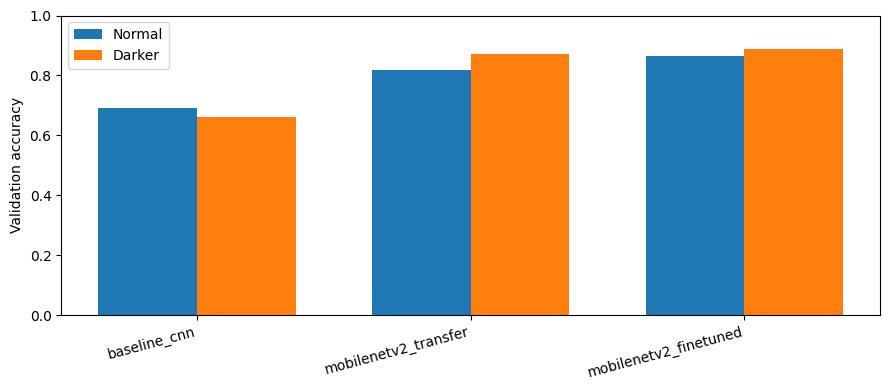

In [10]:
def darken_image(images, labels):
    darker = tf.clip_by_value(tf.cast(images, tf.float32) * 0.65, 0.0, 255.0)
    return darker, labels

dark_val_ds = val_ds.map(darken_image, num_parallel_calls=tf.data.AUTOTUNE)
robustness_results = {}
for name, model in models.items():
    regular = float(validation_results[name]["accuracy"])
    darker = float(model.evaluate(dark_val_ds, verbose=0, return_dict=True)["accuracy"])
    robustness_results[name] = {
        "regular_validation_accuracy": regular,
        "darkened_validation_accuracy": darker,
        "drop_in_accuracy_percentage_points": round((regular - darker) * 100, 2),
    }
    print(f"{name}: normal={regular:.1%}, darker={darker:.1%}")

names = list(robustness_results)
positions = np.arange(len(names))
plt.figure(figsize=(9, 4))
plt.bar(positions - 0.18, [robustness_results[n]["regular_validation_accuracy"] for n in names], width=0.36, label="Normal")
plt.bar(positions + 0.18, [robustness_results[n]["darkened_validation_accuracy"] for n in names], width=0.36, label="Darker")
plt.xticks(positions, names, rotation=15, ha="right")
plt.ylim(0, 1)
plt.ylabel("Validation accuracy")
plt.legend()
plt.tight_layout()
plt.savefig("results/low_light_validation.png", dpi=150)
plt.show()


## 9. Final test measurements and error analysis
**Accuracy** = fraction of correct predictions. **Macro F1-score** gives equal importance to each class, even when one class is more frequent. The confusion matrix shows which classes are mistaken for each other.

baseline_cnn TEST accuracy: 0.6953 macro F1: 0.6876
mobilenetv2_transfer TEST accuracy: 0.8594 macro F1: 0.861
mobilenetv2_finetuned TEST accuracy: 0.8828 macro F1: 0.885

Detailed report for selected model:
                   precision    recall  f1-score   support

angular_leaf_spot       0.93      0.88      0.90        43
        bean_rust       0.78      0.91      0.84        43
          healthy       0.97      0.86      0.91        42

         accuracy                           0.88       128
        macro avg       0.89      0.88      0.88       128
     weighted avg       0.89      0.88      0.88       128



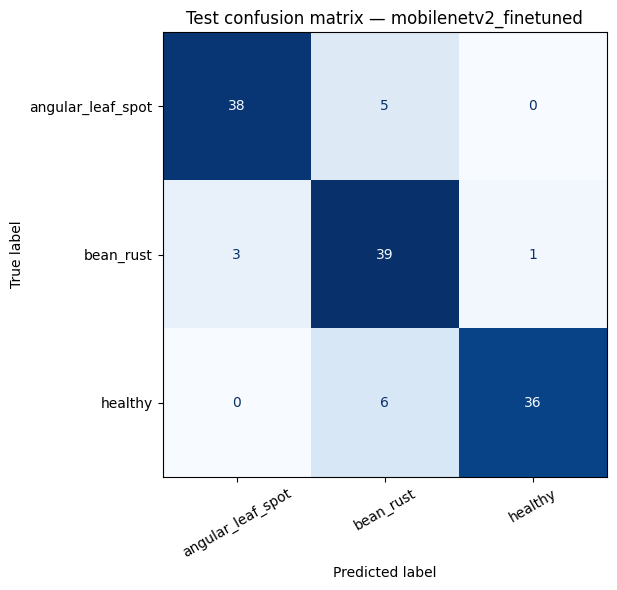

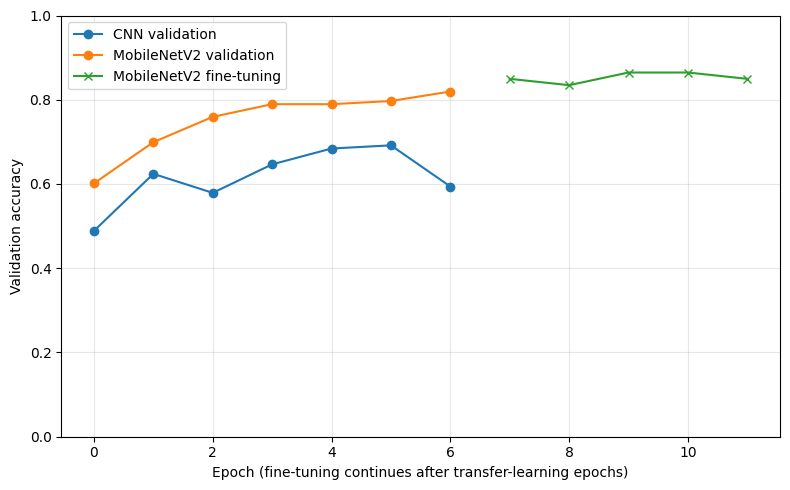

In [11]:
def collect_labels_and_predictions(model, dataset):
    actual_labels = []
    predicted_labels = []
    for images, labels in dataset:
        probabilities = model.predict(images, verbose=0)
        actual_labels.extend(labels.numpy().tolist())
        predicted_labels.extend(np.argmax(probabilities, axis=1).tolist())
    return np.array(actual_labels), np.array(predicted_labels)


def classification_metrics(model, dataset):
    actual, predicted = collect_labels_and_predictions(model, dataset)
    return {
        "accuracy": float(accuracy_score(actual, predicted)),
        "macro_f1": float(f1_score(actual, predicted, average="macro", zero_division=0)),
    }

# Both models are now evaluated once on the test set for final reporting.
test_results = {name: classification_metrics(model, test_ds) for name, model in models.items()}
for name, metrics in test_results.items():
    print(name, "TEST accuracy:", round(metrics["accuracy"], 4),
          "macro F1:", round(metrics["macro_f1"], 4))

actual, predicted = collect_labels_and_predictions(best_model, test_ds)
print("\nDetailed report for selected model:")
print(classification_report(
    actual, predicted, labels=list(range(NUM_CLASSES)),
    target_names=CLASS_NAMES, zero_division=0,
))

cm = confusion_matrix(actual, predicted, labels=list(range(NUM_CLASSES)))
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_NAMES).plot(
    ax=ax, cmap="Blues", xticks_rotation=30, colorbar=False
)
plt.title("Test confusion matrix — " + best_name)
plt.tight_layout()
plt.savefig("results/confusion_matrix.png", dpi=150)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(baseline_history.history["val_accuracy"], marker="o", label="CNN validation")
plt.plot(transfer_history.history["val_accuracy"], marker="o", label="MobileNetV2 validation")
plt.plot(range(len(transfer_history.history["val_accuracy"]), len(transfer_history.history["val_accuracy"]) + len(fine_tune_history.history["val_accuracy"])), fine_tune_history.history["val_accuracy"], marker="x", label="MobileNetV2 fine-tuning")
plt.xlabel("Epoch (fine-tuning continues after transfer-learning epochs)")
plt.ylabel("Validation accuracy")
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("results/validation_accuracy.png", dpi=150)
plt.show()

## 10. Simple prediction demo and post-processing tests
This predicts an image already provided by the test dataset. In Assignment 3, you can replace it with an upload button in a small web app.

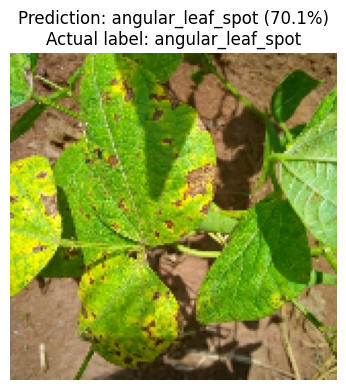

All preprocessing/post-processing tests passed (7 checks).
Prediction confidence is a model score, not a verified medical/agricultural diagnosis.


In [12]:
def label_from_probabilities(probabilities, class_names):
    scores = np.asarray(probabilities, dtype=float)
    if scores.ndim != 1 or scores.shape[0] != len(class_names):
        raise ValueError("Expected one probability per class")
    if not np.all(np.isfinite(scores)):
        raise ValueError("Predictions must be finite numbers")
    return class_names[int(np.argmax(scores))], float(np.max(scores))

# TEST 4 — post-processing chooses the highest-probability label.
assert label_from_probabilities([0.1, 0.8, 0.1], CLASS_NAMES)[0] == CLASS_NAMES[1]
# TEST 5 — malformed model output is rejected.
try:
    label_from_probabilities([0.5, 0.5], CLASS_NAMES)
    raise AssertionError("Incorrect output shape should be rejected")
except ValueError:
    pass

sample_image, sample_true_label = next(iter(test_raw))
sample_image = tf.image.resize(tf.cast(sample_image, tf.float32), IMG_SIZE)
probabilities = best_model.predict(tf.expand_dims(sample_image, axis=0), verbose=0)[0]
assert probabilities.shape == (NUM_CLASSES,)  # TEST 6 — output has three class scores.
assert abs(float(np.sum(probabilities)) - 1.0) < 1e-3  # TEST 7 — scores sum to 1.
predicted_class, predicted_confidence = label_from_probabilities(probabilities, CLASS_NAMES)

plt.figure(figsize=(5, 4))
plt.imshow(tf.cast(sample_image, tf.uint8).numpy())
plt.title(f"Prediction: {predicted_class} ({predicted_confidence:.1%})\n"
          f"Actual label: {CLASS_NAMES[int(sample_true_label.numpy())]}")
plt.axis("off")
plt.tight_layout()
plt.savefig("results/example_prediction.png", dpi=150)
plt.show()
print("All preprocessing/post-processing tests passed (7 checks).")
print("Prediction confidence is a model score, not a verified medical/agricultural diagnosis.")

## 11. Save real results and model
The saved JSON file contains only measured results from this notebook. The `.keras` model file will be useful in Assignment 3 but **do not commit large model files into Git**. Keep it in your Drive, or attach it to a GitHub Release instead.

In [13]:
results = {
    "project": "Plant Disease Detection Using Deep Learning",
    "matriculation_number": "12618839",
    "dataset": "Beans / Makerere AI Lab",
    "classes": CLASS_NAMES,
    "goal_test_accuracy": TARGET_ACCURACY,
    "model_selection_rule": "highest validation accuracy",
    "validation": {name: {key: float(value) for key, value in metrics.items()}
                   for name, metrics in validation_results.items()},
    "test": test_results,
    "validation_lighting_check": robustness_results,
    "selected_model": best_name,
    "training_seconds": {
        "dataset_setup": round(DATA_SECONDS, 2),
        "baseline": round(BASELINE_SECONDS, 2),
        "transfer_learning": round(TRANSFER_SECONDS, 2),
        "fine_tuning": round(FINE_TUNE_SECONDS, 2),
    },
    "environment": {"python": platform.python_version(), "tensorflow": tf.__version__,
                    "tensorflow_datasets": tfds.__version__},
}
with open("results/metrics.json", "w", encoding="utf-8") as f:
    json.dump(results, f, indent=2)

best_model.save("plant_disease_model.keras")
print("Saved results/metrics.json and plant_disease_model.keras")
print("Selected model met target:", test_results[best_name]["accuracy"] >= TARGET_ACCURACY)
print("If target was missed, report that fact and describe possible next experiments.")

Saved results/metrics.json and plant_disease_model.keras
Selected model met target: True
If target was missed, report that fact and describe possible next experiments.


## 12. What to submit
**Assignment 2 deadline:** 15 December 2026.

1. Save a copy of this notebook **with outputs shown** (File → Save a copy in Drive, or Download → Download `.ipynb`).
2. Upload this `.ipynb` and the `results/` figures and `metrics.json` to your existing course GitHub repository, ideally in an `assignment2/` folder.
3. Edit `assignment2/README.md` with your **real** results, the target metric, improvements attempted, and **actual hours** spent (not just your Assignment 1 estimates).
4. Include `requirements.txt`. Do **not** upload the `plant_disease_model.keras` binary directly to the Git repository.
5. Check that the notebook can be run from top to bottom and tests pass.
6. Notify the course team at `applied-deep-learning@outlook.com`, subject: `[Applied Deep Learning] Assignment 2 - 12618839`. Assignment 2 does not require emailing a repository link again if access was already granted.

**Reminder:** This is a learning/classification demonstration for bean leaves, not an agricultural diagnosis system. Field performance is not guaranteed.